# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

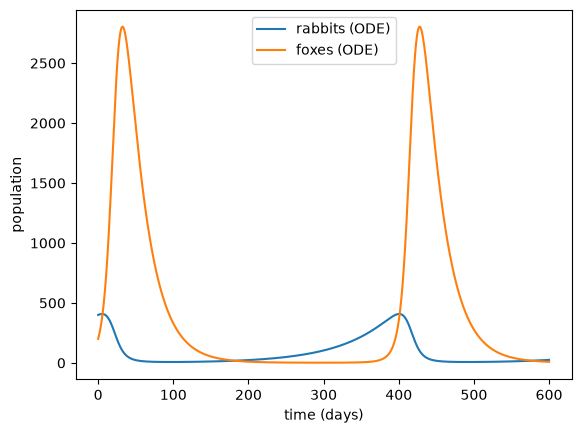

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

Ok so the initial condition is 400 Rabbits and 200 Foxes at t = 0

k is the state i.e. number of rabbits and foxes
Rki is the cumulative sum of rates so Rk1 = r1, Rk2 = r1+r2 and so on

1. There are 4 possible events +1R (r1 = 6) -1R (r2 = 3.2) +1F (r3 = 32) -1F (r4 = 8)

2. Put them all in order on a number line so that there are 4 segments where each segment corresponds to r1 - r4 respectively: 0-6, 6-9.2, 9.2-41.2, 41.2-49.2

3. Qk (sum of all 4 rates) * some random number u (0.5 here) will give us a number and depending on which segment the number falls in it'll be that specific event so 49.2 * 0.5 = 24.6 so event 3 where it's +1F

4. The time where the event occurs is determined by, Delta t = 1/Qk * ln(1/u') (u' = 0.3 here) so delta t = 0.0245 days (35 mins).

5. At t = 0.0245 there are 400 Rabbits and 201 Foxes. You would then recalculate r1,r2,r3, and r4 using the new animal numbers -> recalculate Qk, the segments, pick new uniform random numbers and repeat until Qk = 0 (nothing can happen anymore)

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

In [3]:
def kmc(R0, F0, t_end, rng):
    t, R, F = 0.0, R0, F0
    times, rabbits, foxes = [t], [R], [F]

    while t < t_end:
        # Step 1: the four rates, from the current R and F
        rates = np.array([k1*R,k2*R*F,k3*R*F,k4*F])           # k1*R, k2*R*F, ...

        # Step 2: cumulative rates (segment boundaries) and total
        cumulative = np.cumsum(rates)     # [R_k1, R_k2, R_k3, R_k4]
        Q = cumulative[-1]
        if Q == 0:
            break                         # nothing can happen any more

        # Step 3: pick the event
        u = 1 - rng.random()                           # uniform random number in (0, 1]
        i = np.searchsorted(cumulative, u * Q)     # which segment u*Q falls in (0, 1, 2 or 3)

        # Step 5: apply the event
        if i == 0:
            R += 1
        elif i == 1:
            R -= 1
        elif i == 2:
            F += 1
        elif i == 3:
            F -= 1
        else:
            raise ValueError(f"unknown event {i}")
        if R < 0 or F < 0:
            raise ValueError(f"negative population at t={t}: R={R}, F={F}")

        # Step 4: advance the clock
        u_prime = 1 - rng.random()                     # second, independent random number
        t += np.log(1 / u_prime) / Q               # Delta t = ln(1/u') / Q

        times.append(t); rabbits.append(R); foxes.append(F)

    return np.array(times), np.array(rabbits), np.array(foxes)

14996 events in 0.34528565406799316 seconds
final time: 600.0255201797252  final R: 2224  final F: 0


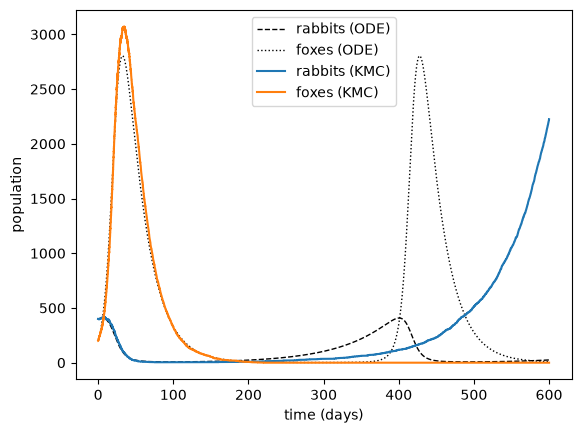

In [4]:
rng = np.random.default_rng(42)
start = time.time()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
print(len(times) - 1, "events in", time.time() - start, "seconds")

print("final time:", times[-1], " final R:", rabbits[-1], " final F:", foxes[-1])

plt.plot(t_ode, R_ode, "k--", lw=1, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, "k:", lw=1, label="foxes (ODE)")
plt.step(times, rabbits, where="post", label="rabbits (KMC)")
plt.step(times, foxes, where="post", label="foxes (KMC)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

seed 1: 24813 events, foxes survived (F = 1)


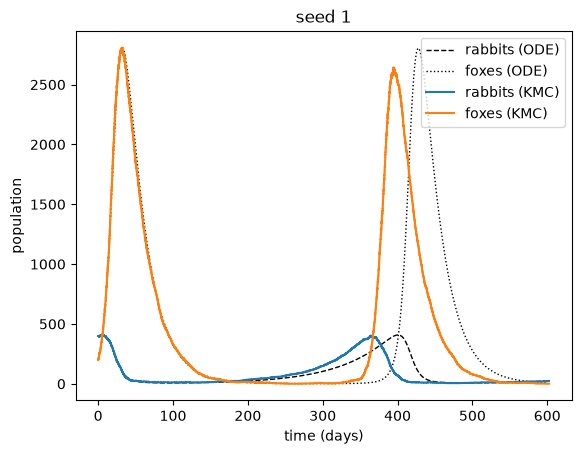

seed 2: 15487 events, foxes extinct at day 285


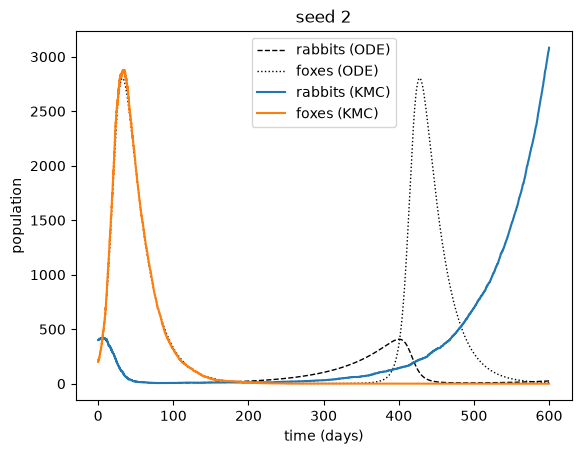

seed 3: 18356 events, foxes extinct at day 335


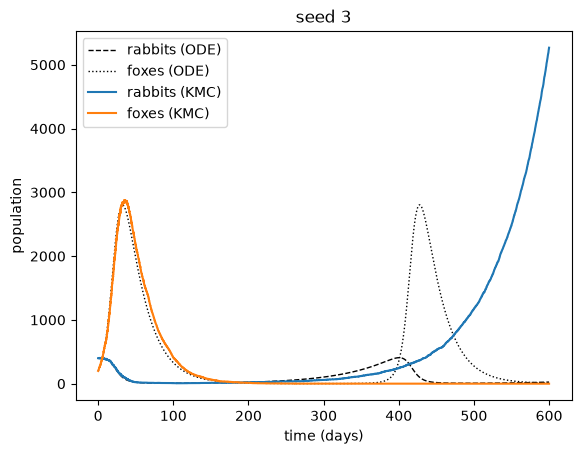

seed 4: 16490 events, foxes extinct at day 298


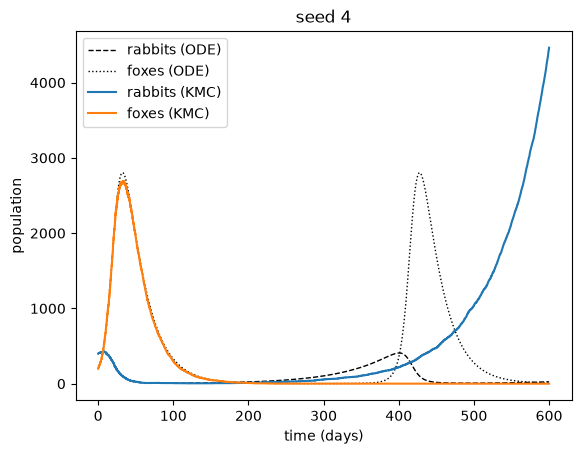

seed 5: 25354 events, foxes survived (F = 2)


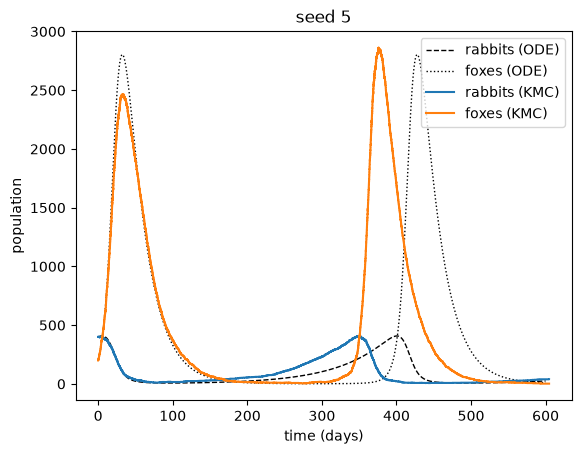

In [5]:
for seed in [1, 2, 3, 4, 5]:
    rng = np.random.default_rng(seed)
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    if foxes[-1] == 0:
        extinct = times[np.argmax(foxes == 0)]
        print(f"seed {seed}: {len(times)-1} events, foxes extinct at day {extinct:.0f}")
    else:
        print(f"seed {seed}: {len(times)-1} events, foxes survived (F = {foxes[-1]})")

    plt.plot(t_ode, R_ode, "k--", lw=1, label="rabbits (ODE)")
    plt.plot(t_ode, F_ode, "k:", lw=1, label="foxes (ODE)")
    plt.step(times, rabbits, where="post", label="rabbits (KMC)")
    plt.step(times, foxes, where="post", label="foxes (KMC)")
    plt.title(f"seed {seed}")
    plt.xlabel("time (days)")
    plt.ylabel("population")
    plt.legend()
    plt.show()

*Answer:* 14,996 events in 0.32 seconds for seed 42

KMC is similar to ODE for large populations until it drops. ODE can recover and continue breeding from a fractional number number whereas in KMC foxes can go extinct and the rabbits grow exponentially with nothing eating them

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

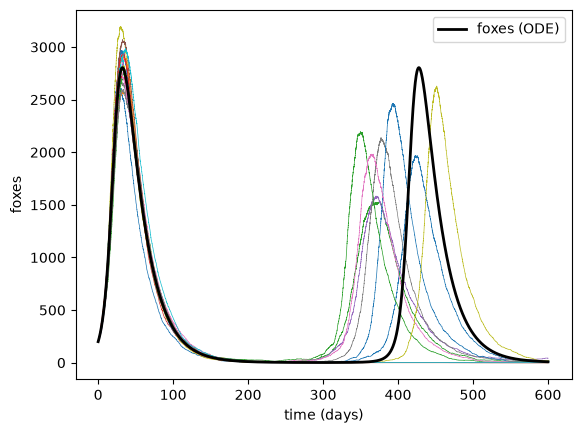

In [6]:
rng = np.random.default_rng(2026)

for run in range(20):
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    plt.step(times, foxes, where="post", lw=0.5)

plt.plot(t_ode, F_ode, "k", lw=2, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("foxes")
plt.legend()
plt.show()

*Answer:*
What do the trajectories have in common, and where do they spread apart?

They all have an initial peak between 0 - 100 days between 2500 and 3200 then all fall together. Some of the KMC graphs go to 0 and others form a 2nd peak later on. The second set of peaks are much more scattered and less uniform than the first set of peaks. All second peak KMC graphs are lower than the ODE and most are earlier.

What happens to a trajectory once the foxes reach zero? Once the rabbits reach zero? Why can't it ever recover?

the event where a Fox is born and so +1F is based on some rate constant times F and R, if F or R is 0 there will never be another fox born. if F is 0 then no rabbits can be eaten and number of rabbits will never decrease leading to exponential growth, if R is 0 then rabbits can never be born

Where in the cycle do the foxes usually die out, and why there? (Your answer to task 5 of the solve_ivp homework is relevant.)

Between 200-300. When R<100 a fox is more likely to die than breed.




## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

In [7]:
def second_peak(times, foxes):
    window = (times >= 200) & (times <= 600)
    t_win = times[window]
    f_win = foxes[window]
    if len(f_win) == 0:
        return None

    j = np.argmax(f_win)
    t_peak = t_win[j]
    height = f_win[j]

    if height <= 100 or t_peak < 205 or t_peak > 595:
        return None
    return t_peak, height

print(second_peak(t_ode, F_ode))

for seed in [42, 1]:
    rng = np.random.default_rng(seed)
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    print(seed, second_peak(times, foxes))

(np.float64(427.8), np.float64(2803.8679140358477))
42 None
1 (np.float64(394.75126212977455), np.int64(2642))


In [8]:
rng = np.random.default_rng(2026)
n_runs = 100
peak_times, peak_heights = [], []

start = time.time()
for run in range(n_runs):
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    peak = second_peak(times, foxes)
    if peak is not None:
        peak_times.append(peak[0])
        peak_heights.append(peak[1])

peak_times = np.array(peak_times)
peak_heights = np.array(peak_heights)
print(f"{len(peak_times)} of {n_runs} runs have a second peak")
print(f"took {time.time() - start:.1f} seconds")

30 of 100 runs have a second peak
took 44.8 seconds


In [9]:
print("time:   mean", np.mean(peak_times), " median", np.median(peak_times),
      " IQR", np.percentile(peak_times, 25), "to", np.percentile(peak_times, 75))
print("height: mean", np.mean(peak_heights), " median", np.median(peak_heights),
      " IQR", np.percentile(peak_heights, 25), "to", np.percentile(peak_heights, 75))

time:   mean 391.80495522492316  median 386.9634636278784  IQR 371.6168046584919 to 407.99839396823876
height: mean 2182.8  median 2188.0  IQR 1827.0 to 2523.75


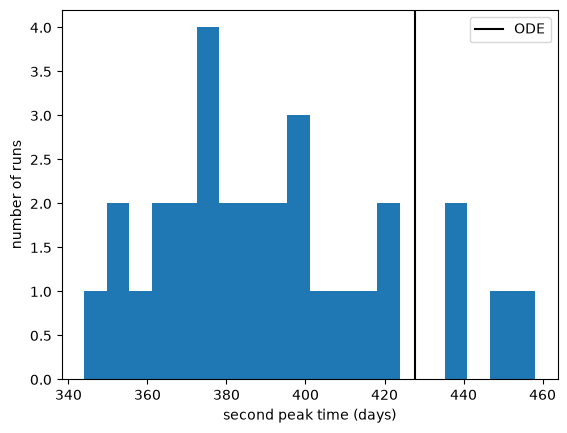

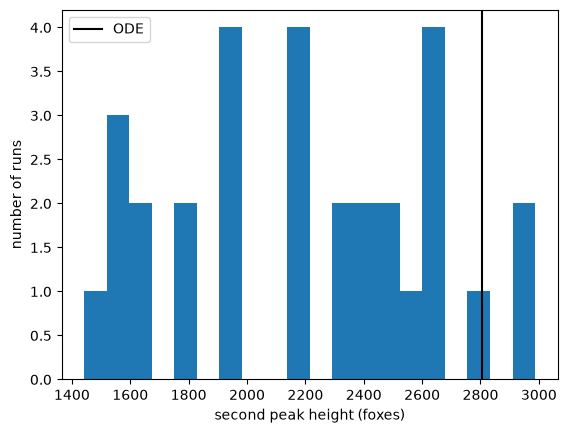

In [10]:
plt.hist(peak_times, bins=20)
plt.axvline(427.8, color="k", label="ODE")
plt.xlabel("second peak time (days)")
plt.ylabel("number of runs")
plt.legend()
plt.show()

plt.hist(peak_heights, bins=20)
plt.axvline(2804, color="k", label="ODE")
plt.xlabel("second peak height (foxes)")
plt.ylabel("number of runs")
plt.legend()
plt.show()

In [11]:
rng = np.random.default_rng(2026)
for run in range(100):
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    peak = second_peak(times, foxes)
    if peak is None:
        window = (times >= 200) & (times <= 600)
        if window.any() and foxes[window].max() > 100:
            print(run, "rejected: max", foxes[window].max(), "at day", times[window][np.argmax(foxes[window])])
    elif peak[0] < 250 or peak[0] > 550:
        print(run, "suspicious peak:", peak)

*Answer:*

30/100 runs had a second peak, 70 other runs foxes died in the trough. 

time:   mean 392  median 387  IQR 372 to 408
height: mean 2182.8  median 2188.0  IQR 1827.0 to 2523.75

ODe's 2nd peak is later and higher than most KMC peaks. Above 75th percentile for time and height.

The runs that have a 2nd peak kept more foxes than the ODE (1.6). Starting from more means they grow sooner, foxes start eating rabbits sooner rabbits dont recover as far as in the ODE so peak is lower, they peak earlier and grow sooner.

a second peak after 595 days would be rejected so the bias is towards early peaks. A slowly falling first peak could have more than 100 foxes at day 205 and would be counted as a second peak. A second peak below 100 foxes isnt counted. The 100 run check didn't find any of these cases since all 2nd peaks were between 345 and 460

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

In [12]:
def run_many(n_runs, rng):
    peak_times, peak_heights, extinction_times = [], [], []
    for run in range(n_runs):
        times, rabbits, foxes = kmc(R0, F0, t_end, rng)
        peak = second_peak(times, foxes)
        if peak is not None:
            peak_times.append(peak[0])
            peak_heights.append(peak[1])
        if foxes[-1] == 0:
            extinction_times.append(times[np.argmax(foxes == 0)])
    return np.array(peak_times), np.array(peak_heights), np.array(extinction_times)

In [13]:
rng = np.random.default_rng(2027)
results = {}
for n in [100, 300, 1000, 3000]:
    start = time.time()
    results[n] = run_many(n, rng)
    print(f"{n} runs: {time.time() - start:.0f} s, {len(results[n][0])} with a second peak")

100 runs: 42 s, 31 with a second peak
300 runs: 128 s, 99 with a second peak
1000 runs: 398 s, 334 with a second peak
3000 runs: 1127 s, 934 with a second peak


In [14]:
for n in [100, 300, 1000, 3000]:
    pt, ph, ext = results[n]
    m = len(pt)
    se_t = np.std(pt, ddof=1) / np.sqrt(m)
    se_h = np.std(ph, ddof=1) / np.sqrt(m)
    print(f"N={n:5d}  peaks={m:4d}  "
          f"time {np.mean(pt):6.1f} ± {se_t:4.1f}   height {np.mean(ph):7.1f} ± {se_h:5.1f}")

N=  100  peaks=  31  time  400.5 ±  6.4   height  2352.9 ± 101.3
N=  300  peaks=  99  time  403.0 ±  2.9   height  2452.6 ±  65.2
N= 1000  peaks= 334  time  401.0 ±  1.6   height  2342.8 ±  30.7
N= 3000  peaks= 934  time  399.6 ±  1.0   height  2336.3 ±  19.0


In [15]:
pt, ph, ext = results[3000]
print("IQR time:", np.percentile(pt, [25, 75]), " IQR height:", np.percentile(ph, [25, 75]))

IQR time: [379.471723   418.43122624]  IQR height: [1911.25 2649.5 ]


*Answer:*

Task 3 ran for 39.6 s so I'd assume 30 times longer for the 3000 run. The actual times were 41 s, 122 s, 402 s and 1,174 s. for each run respectively

The mean second peak time was 400.5, 403.0, 401.0 and 399.6 days, and the mean height 2,353, 2,453, 2,343 and 2,336 foxes, for N = 100, 300, 1,000 and 3,000. The changes are within a couple of standard errors, so they’re random noise that gets smaller with more runs. About 31 to 33% of runs had a second peak at every N.

The standard error of the mean time fell from 6.4 to 1.0 days, and of the height from 101 to 19 foxes, as the number of peaks went from 31 to 934. That’s about 30 times more data, and sqrt of 30 ~ 5.5. To halve the uncertainty, you need four times as many runs. The errors shrank by about 6.4 and 5.3, close to 5.5, so the standard error scales as 1 / sqrt (n).

From 3,000 runs (934 with a second peak): time 400 +- 1 days, IQR 379 to 418 days; height 2,340 +- 20 foxes, IQR 1,910 to 2,650 foxes.

I rounded each mean so its last digit matches its standard error, because digits smaller than the uncertainty aren’t meaningful. The IQRs are much wider than the standard errors because they describe how much individual runs differ, which doesn’t shrink with more runs.


## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

In [16]:
pt, ph, ext = results[3000]
N = 3000
ext600 = ext[ext <= t_end]
p = len(ext600) / N
se_p = np.sqrt(p * (1 - p) / N)
print(f"foxes extinct by day 600 in {len(ext600)} of {N} runs: p = {p:.3f} ± {se_p:.3f}")
print(f"{len(ext) - len(ext600)} more runs lost their last fox in the final step, after day 600")

foxes extinct by day 600 in 2111 of 3000 runs: p = 0.704 ± 0.008
9 more runs lost their last fox in the final step, after day 600


In [17]:
for target in [0.01, 0.001]:
    N_needed = p * (1 - p) / target**2
    print(f"for ±{target*100:.1f} percentage points: about {N_needed:,.0f} runs "
          f"({N_needed * 0.396 / 3600:.1f} hours at 0.396 s per run)")

for ±1.0 percentage points: about 2,085 runs (0.2 hours at 0.396 s per run)
for ±0.1 percentage points: about 208,520 runs (22.9 hours at 0.396 s per run)


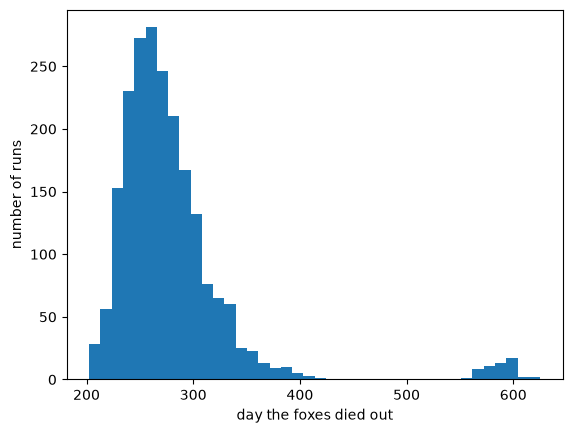

In [18]:
plt.hist(ext, bins=40)
plt.xlabel("day the foxes died out")
plt.ylabel("number of runs")
plt.show()

*Answer:*

Out of 3,000 runs, 2,111 had no foxes left at day 600, so p = 0.704 ± 0.008, about 70 +- 1%. The first count (2,120) included 9 runs where the last fox died in the final step, after day 600, counting only extinctions by day 600 changed p from 0.707 to 0.704, less than one standard error. This fits task 4, where about 31% of runs had a second peak.

For +-1 percentage point I’d need about 2,100 runs, which my 3,000 already exceeds. For +-0.1 percentage point I’d need about 209,000 runs, about 23 hours at 0.4 s per run. 100 times more runs for 10 times more precision, because the standard error scales as 1 / sqrt (N), so it would only be practical as a batch job on Explorer or with faster code. For a 95% confidence interval, both numbers would be 4 times larger.

Most extinctions happen between days 200 and 420, peaking around day 250 to 280, in the first trough. There, the foxes are down to one or two and the rabbits are below 100, so each fox is more likely to die than to breed. A second, smaller group near day 560 - 600 is runs that survived the first trough, made a second peak, and are dying out in the second trough. There are no extinctions between about 420 and 560, because during the second peak there are hundreds or thousands of foxes.





## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

My project would be on modeling the dissolution and absorption of drug from buccal films. I think a continuum model (Fick’s-law diffusion through the film and mucosa, and ODEs for absorption) should be good enough for the drug concentration, even a low dose film contains around 10^16 or more drug molecules, so random fluctuations are about one part in 10^8 so randomness is negligible. I suppose swallowing is a discrete, random event, removing saliva and dissolved drug in chunks roughly every minute rather than as a smooth outflow, which could matter when deciding how much drug is absorbed through the cheek versus swallowed. In a KMC model, the event would be a swallow, happening at a rate of about once per minute, and each swallow would remove the drug dissolved in the saliva at that moment

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.